In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm
from scipy.optimize import curve_fit
def gaussian(x, a, mu, c):
    return a * np.exp(-(x - mu)**2 / (2 * c**2))

# Function for finding photopeak, modified from ChannelPairBuilder.py
def findPhotopeak(hist, bins):
    photopeak = 0
    for i in range(1, len(hist)-4):
        #if hist[-1*i] > hist[-1*(i+1)] and hist[-1*i] > hist[-1*(i+2)] and hist[-1*i] >= 0.5 * np.max(hist):
        if hist[-1*i] >= 0.5 * np.max(hist[len(hist) // 4:]):
            photopeak = len(hist)-1*i
            break
    fit_p = [0,1,1]
    fit_x = list(bins[photopeak-5:photopeak+10])
    fit_y = list(hist[photopeak-5:photopeak+10])

    if len(fit_x) != 0 and len(fit_y) != 0:
        try:
            fit_p, _ = curve_fit(gaussian, fit_x, fit_y, p0=[max(fit_y)*0.8, bins[photopeak], 2])
        except:
            pass
    return fit_p

In [3]:
path = '/home/kale-chen/Documents/PET/MiniPET/OldData/PCB3_19-selected/Run118_coinc.dat'
df = pd.read_csv(path, header=None, sep = '\t', usecols = [2, 3, 4, 7, 8, 9])
df.columns = ['TimeL', 'EnergyL', 'IDL', 'TimeR', 'EnergyR', 'IDR']
t0 = df['TimeL'].iloc[0]
df['TimeL'] = (df['TimeL'] - t0) * 1e-12
df['TimeR'] = (df['TimeR'] - t0) * 1e-12
df['IDL'] = df['IDL'] % 128
df['IDR'] = df['IDR'] % 128
data = np.asarray(df)
print(len(data))
print(data[0:3])

2735488
[[ 0.00000000e+00  1.77385700e+00  8.50000000e+01 -1.78800000e-09
   2.15335960e+01  5.30000000e+01]
 [ 7.00721411e-04  1.12405620e+01  1.00000000e+00  7.00721281e-04
   1.84933170e+01  9.50000000e+01]
 [ 1.04796447e-03  2.61475910e+01  6.60000000e+01  1.04796697e-03
   2.29608650e+01  5.10000000e+01]]


94
[2.76407092e+03 2.72996054e+01 7.19074940e-01] [3.06463485e+03 2.28676032e+01 6.78997587e-01]
24661 10073 24658 10529


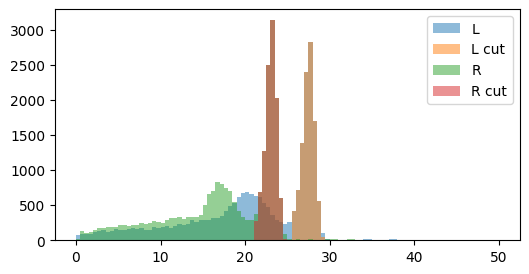

In [5]:
randomid = np.random.randint(0, 128)
print(randomid)
energiesL = data[data[:, 2] == randomid, 1]
energiesR = data[data[:, 5] == randomid, 4]
plt.figure(figsize=(6, 3))
hist, bins = plt.hist(energiesL, bins=100, range=(0, 50), alpha=0.5, label='L')[0:2]
fitL = findPhotopeak(hist, bins)
energiesLcut = energiesL[(energiesL > fitL[1] - 2.5 * fitL[2]) & (energiesL < fitL[1] + 2.5 * fitL[2])]
plt.hist(energiesLcut, bins=100, range=(0, 50), alpha=0.5, label='L cut')
hist, bins = plt.hist(energiesR, bins=100, range=(0, 50), alpha=0.5, label='R')[0:2]
fitR = findPhotopeak(hist, bins)
energiesRcut = energiesR[(energiesR > fitR[1] - 2.5 * fitR[2]) & (energiesR < fitR[1] + 2.5 * fitR[2])]
plt.hist(energiesRcut, bins=100, range=(0, 50), alpha=0.5, label='R cut')
plt.legend()
print(fitL, fitR)
print(len(energiesL), len(energiesLcut), len(energiesR), len(energiesRcut))
plt.show()


In [60]:
# Pcutter
photopeakfitsL = []
photopeakfitsR = []
maskL = np.zeros(len(data), dtype=bool)
maskR = np.zeros(len(data), dtype=bool)
cr = 2.5
for id in tqdm(range(128)):
    energiesL = data[data[:, 2] == id, 1]
    hist, bins = np.histogram(energiesL, bins=100, range=(0, 50))
    fitL = findPhotopeak(hist, bins)
    photopeakfitsL.append(fitL)
    maskL = maskL | ((data[:, 1] > fitL[1] - cr * fitL[2]) & (data[:, 1] < fitL[1] + cr * fitL[2]) & (data[:, 2] == id))
    energiesR = data[data[:, 5] == id, 4]
    hist, bins = np.histogram(energiesR, bins=100, range=(0, 50))
    fitR = findPhotopeak(hist, bins)
    photopeakfitsR.append(fitR)
    maskR = maskR | ((data[:, 4] > fitR[1] - cr * fitR[2]) & (data[:, 4] < fitR[1] + cr * fitR[2]) & (data[:, 5] == id))
print(np.sum(maskL), np.sum(maskR))
datapcut = data[maskL & maskR]
print(len(datapcut))
print(datapcut[0:3])

100%|██████████| 128/128 [00:02<00:00, 59.28it/s]

1163832 1175941
509899
[[1.04796447e-03 2.61475910e+01 6.60000000e+01 1.04796697e-03
  2.29608650e+01 5.10000000e+01]
 [5.64377289e-03 2.64958110e+01 1.06000000e+02 5.64377227e-03
  2.28906360e+01 2.50000000e+01]
 [6.60197664e-03 2.75891950e+01 1.10000000e+01 6.60197770e-03
  2.23867420e+01 1.25000000e+02]]
